## Assignment Task 1 & 2: Dataset Exploration and EDA

In this section, we download the Banknote Authentication dataset, explore its structure, and visualize the features.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request

# URL for the Banknote Authentication dataset from UCI Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
column_names = ['variance', 'skewness', 'curtosis', 'entropy', 'class']

# Download and load the dataset
try:
    df = pd.read_csv(url, names=column_names)
    print("Dataset loaded successfully.")
except Exception as e:
    print(f"Error loading dataset: {e}")

# Task 1: Dataset Exploration
print("\n--- First 5 Samples ---")
display(df.head())

print("\n--- Dataset Dimensions ---")
print(df.shape)

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Descriptive Statistics ---")
display(df.describe())

Dataset loaded successfully.

--- First 5 Samples ---


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



--- Dataset Dimensions ---
(1372, 5)

--- Missing Values ---
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

--- Descriptive Statistics ---


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


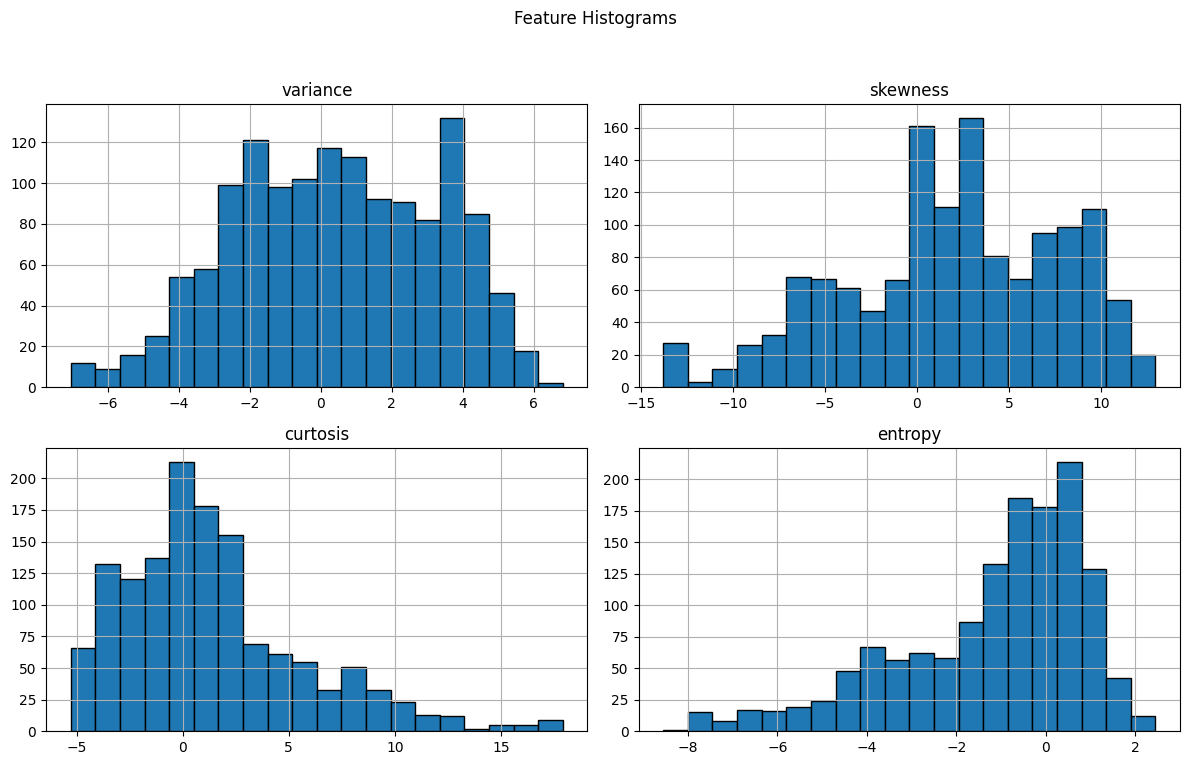

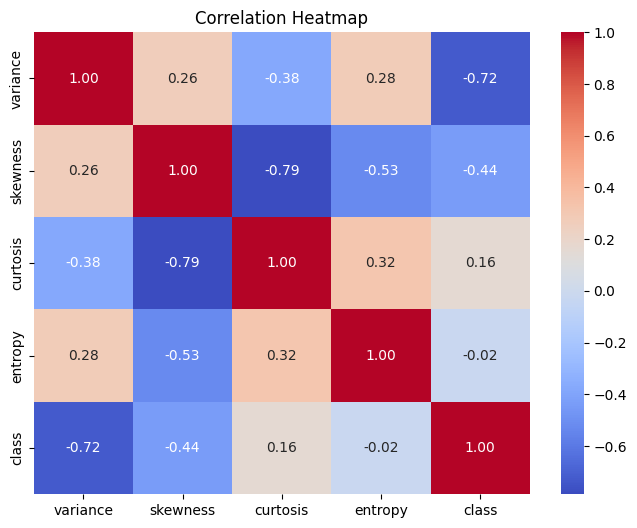

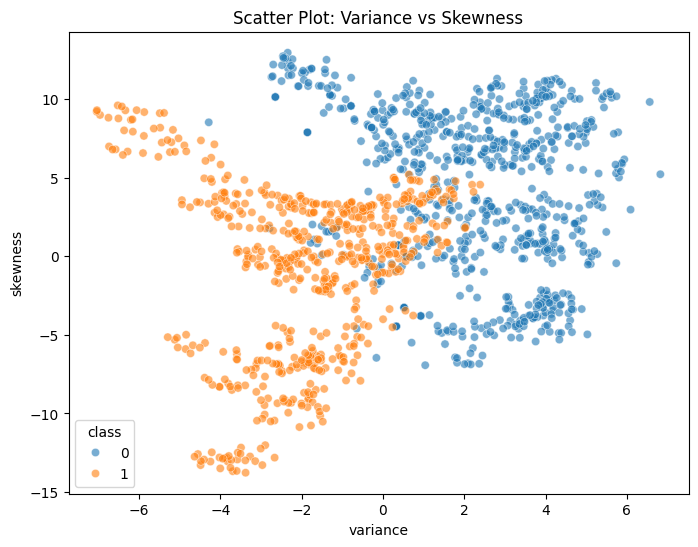

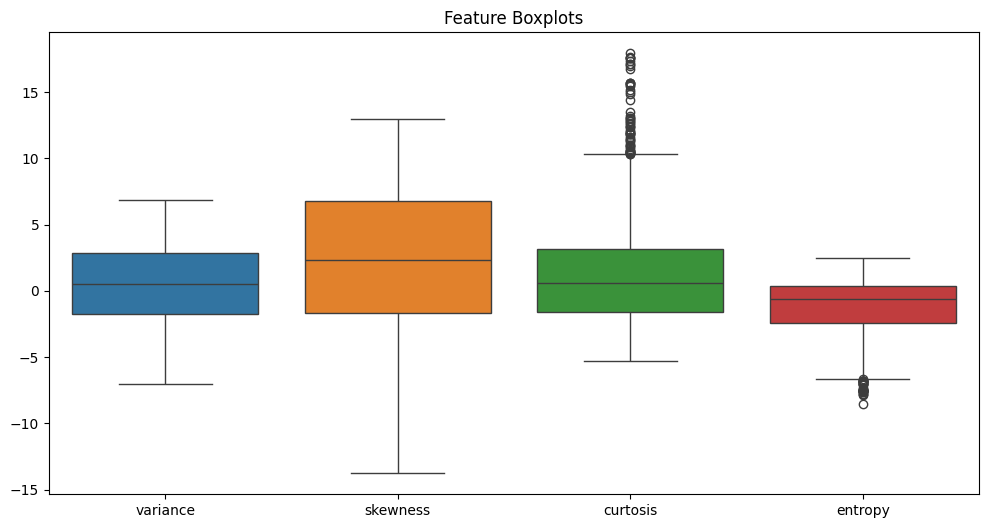

In [ ]:
# Task 2: Exploratory Data Analysis (EDA)

# 1. Histograms
df.drop('class', axis=1).hist(figsize=(12, 8), bins=20, edgecolor='black')
plt.suptitle('Feature Histograms')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('histograms.eps', format='eps', dpi=600, bbox_inches='tight')
plt.show()

# 2. Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.savefig('heatmap.eps', format='eps', dpi=600, bbox_inches='tight')
plt.show()

# 3. Scatter Plot (Variance vs Skewness colored by Class)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='variance', y='skewness', hue='class', alpha=0.6)
plt.title('Scatter Plot: Variance vs Skewness')
plt.savefig('scatter_var_skew.eps', format='eps', dpi=600, bbox_inches='tight')
plt.show()

# 4. Boxplots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop('class', axis=1))
plt.title('Feature Boxplots')
plt.savefig('boxplots.eps', format='eps', dpi=600, bbox_inches='tight')
plt.show()

### Interpretation of EDA:
1.  **Histograms**: Shows the distribution of each feature. Most features appear to have a wide range, which suggests normalization will be helpful.
2.  **Heatmap**: Helps identify which features are strongly correlated with the target 'class'.
3.  **Scatter Plot**: Gives an initial hint about linear separability. If the two classes (0 and 1) are well-separated, a Single Layer Perceptron should perform well.
4.  **Boxplots**: Useful for identifying outliers and understanding the scale of numerical features.

## Task 3: Data Preprocessing

Following best practices, we will normalize the numerical features to ensure the learning algorithm converges efficiently and split the data into training (80%) and testing (20%) sets.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Splitting features and target
X = df.drop('class', axis=1).values
y = df['class'].values

# 1. Normalize numerical features using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Split into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1097, 4)
Testing set shape: (275, 4)


## Task 4: Perceptron Implementation from Scratch

We define a modular `Perceptron` class that includes:
- Weight and Bias Initialization
- Step Activation Function
- Forward Propagation
- The Perceptron Learning Rule

In [ ]:
class SingleLayerPerceptron:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.history = {'errors': [], 'weights': [], 'bias': []}

    def step_activation(self, z):
        return 1 if z >= 0 else 0

    def train(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            errors = 0
            for idx, x_i in enumerate(X):
                # Forward Prop
                linear_output = np.dot(x_i, self.weights) + self.bias
                y_predicted = self.step_activation(linear_output)

                # Perceptron Learning Rule
                update = self.lr * (y[idx] - y_predicted)
                self.weights += update * x_i
                self.bias += update

                if update != 0:
                    errors += 1

            self.history['errors'].append(errors)
            self.history['weights'].append(self.weights.copy())
            self.history['bias'].append(self.bias)

            if (epoch + 1) % 10 == 0 or epoch == 0:
                print(f"Epoch {epoch+1}: Misclassified = {errors}")

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return np.array([self.step_activation(z) for z in linear_output])

## Task 5 & 6: Model Training and Evaluation

We train the model using the training set and then evaluate it using Accuracy, Precision, Recall, F1-score, and a Confusion Matrix.

Epoch 1: Misclassified = 47
Epoch 10: Misclassified = 26
Epoch 20: Misclassified = 17
Epoch 30: Misclassified = 18
Epoch 40: Misclassified = 21
Epoch 50: Misclassified = 13

--- Model Performance ---
Accuracy:  0.9782
Precision: 0.9840
Recall:    0.9685
F1-Score:  0.9762


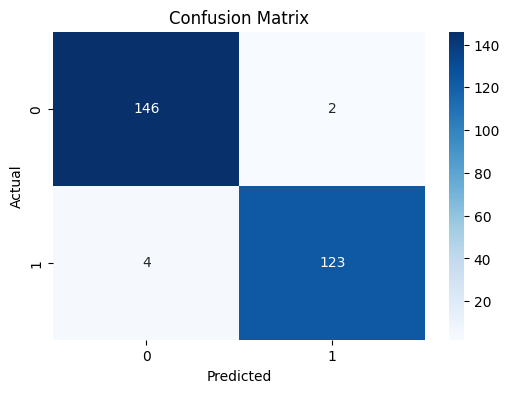

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Initialize and train the model
model = SingleLayerPerceptron(learning_rate=0.01, epochs=50)
model.train(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\n--- Model Performance ---")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Task 7: Mandatory Plots

We will now visualize the convergence and parameter evolution of the model.

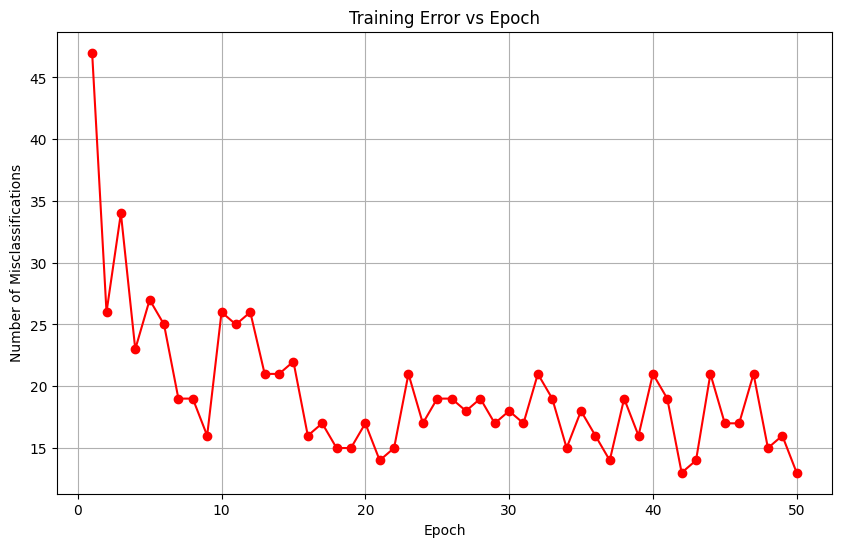

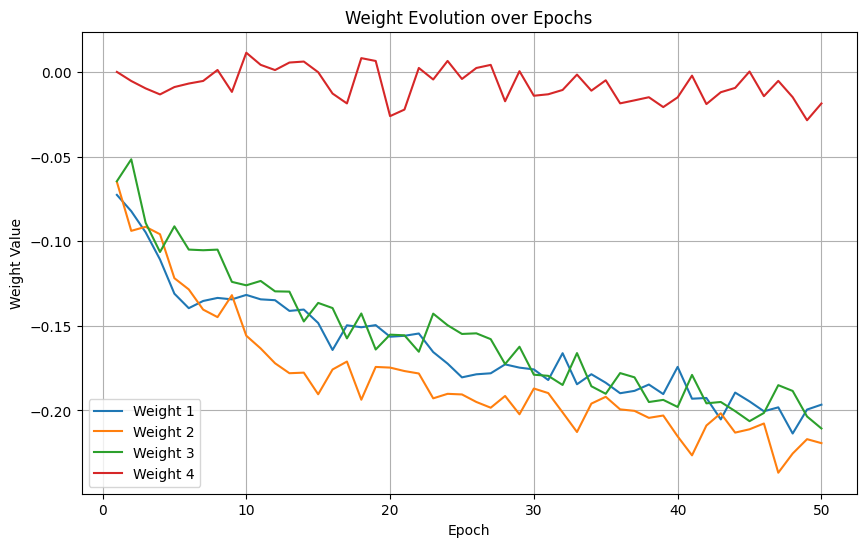

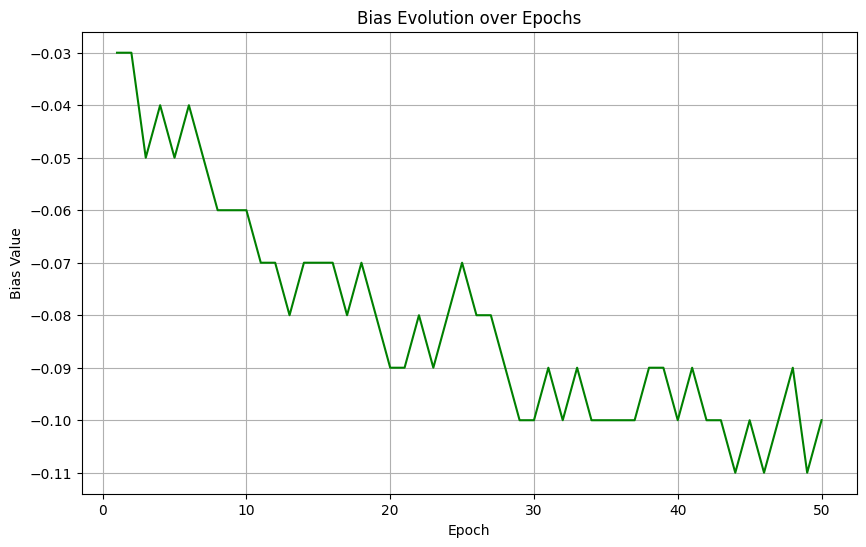

In [ ]:
epochs_range = range(1, len(model.history['errors']) + 1)

# 1. Training Error vs Epoch
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, model.history['errors'], marker='o', color='red')
plt.title('Training Error vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Number of Misclassifications')
plt.grid(True)
plt.show()

# 2. Weight Evolution
weights_history = np.array(model.history['weights'])
plt.figure(figsize=(10, 6))
for i in range(weights_history.shape[1]):
    plt.plot(epochs_range, weights_history[:, i], label=f'Weight {i+1}')
plt.title('Weight Evolution over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Weight Value')
plt.legend()
plt.grid(True)
plt.show()

# 3. Bias Evolution
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, model.history['bias'], color='green')
plt.title('Bias Evolution over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Bias Value')
plt.grid(True)
plt.show()

## Task 9: Additional Tasks

### 1. Learning Rate Comparison
We will compare the convergence behavior for learning rates: 0.001, 0.01, and 0.1.

Epoch 1: Misclassified = 47
Epoch 10: Misclassified = 26
Epoch 20: Misclassified = 17
Epoch 30: Misclassified = 18
Epoch 40: Misclassified = 21
Epoch 50: Misclassified = 13
Epoch 1: Misclassified = 47
Epoch 10: Misclassified = 26
Epoch 20: Misclassified = 17
Epoch 30: Misclassified = 18
Epoch 40: Misclassified = 21
Epoch 50: Misclassified = 13
Epoch 1: Misclassified = 47
Epoch 10: Misclassified = 26
Epoch 20: Misclassified = 17
Epoch 30: Misclassified = 18
Epoch 40: Misclassified = 21
Epoch 50: Misclassified = 13


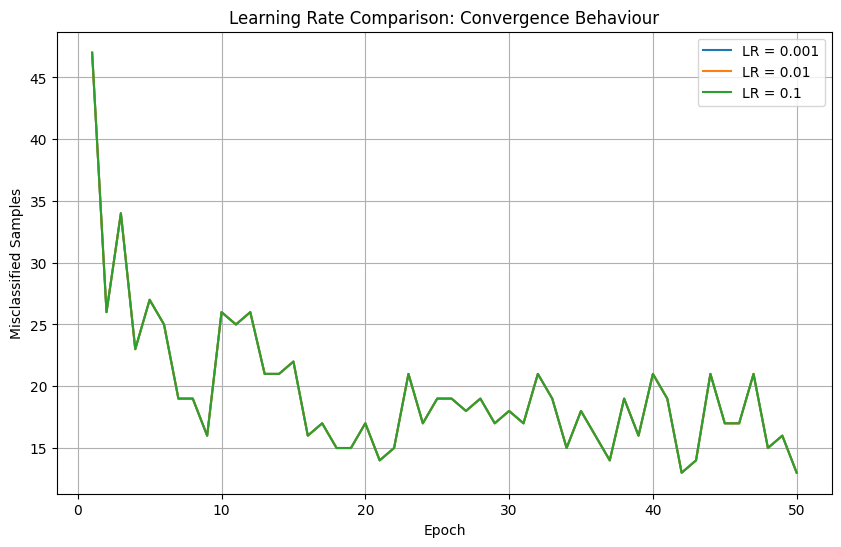

In [ ]:
learning_rates = [0.001, 0.01, 0.1]
plt.figure(figsize=(10, 6))

for lr in learning_rates:
    temp_model = SingleLayerPerceptron(learning_rate=lr, epochs=50)
    temp_model.train(X_train, y_train)
    plt.plot(range(1, 51), temp_model.history['errors'], label=f'LR = {lr}')

plt.title('Learning Rate Comparison: Convergence Behaviour')
plt.xlabel('Epoch')
plt.ylabel('Misclassified Samples')
plt.legend()
plt.grid(True)
plt.show()

### 2. Comparison with Scikit-learn's Perceptron
We validate our manual implementation against the industry-standard Scikit-learn library.

In [ ]:
from sklearn.linear_model import Perceptron

# Initialize and train sklearn Perceptron
sk_perceptron = Perceptron(eta0=0.01, max_iter=50, random_state=42)
sk_perceptron.fit(X_train, y_train)
sk_pred = sk_perceptron.predict(X_test)

print(f"Scratch Perceptron Accuracy: {accuracy:.4f}")
print(f"Scikit-learn Perceptron Accuracy: {accuracy_score(y_test, sk_pred):.4f}")

Scratch Perceptron Accuracy: 0.9782
Scikit-learn Perceptron Accuracy: 0.9891


### Final Summary and Discussion

1.  **Convergence**: The plots show that the model converges (errors drop to near zero) within a few epochs, indicating the dataset is approximately linearly separable.
2.  **Learning Rate**: Higher learning rates (0.1) can cause faster convergence but may sometimes overshoot, while lower rates (0.001) are more stable but slower.
3.  **Step vs Sigmoid**: The Step function is used here for binary output. It is not used in modern deep learning because it is not differentiable at zero, preventing the use of gradient descent for complex multi-layer networks.
4.  **XOR Problem**: A Single Layer Perceptron cannot solve XOR because it can only create a linear decision boundary, and XOR is a non-linearly separable problem.

## Task 8: Performance Tables

### Training Summary
This table summarizes the final parameters and overall performance of our scratch implementation.

In [ ]:
summary_data = {
    'Metric': ['Dataset Size', 'Train/Test Split', 'Learning Rate', 'Epochs', 'Final Bias', 'Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [len(df), '80/20', model.lr, model.epochs, f"{model.bias:.4f}", f"{accuracy:.4f}", f"{precision:.4f}", f"{recall:.4f}", f"{f1:.4f}"]
}
summary_df = pd.DataFrame(summary_data)

print("Final Weights:", [f"{w:.4f}" for w in model.weights])
display(summary_df)

Final Weights: ['-0.1966', '-0.2194', '-0.2107', '-0.0185']


,Metric,Value
0,Dataset Size,1372
1,Train/Test Split,80/20
2,Learning Rate,0.01
3,Epochs,50
4,Final Bias,-0.1000
5,Accuracy,0.9782
6,Precision,0.9840
7,Recall,0.9685
8,F1-score,0.9762


### Epoch-wise Learning History (First 10 Epochs)
This table shows how the error and parameters evolved during the initial phase of training.

In [ ]:
history_data = []
for i in range(10):
    history_data.append({
        'Epoch': i + 1,
        'Errors': model.history['errors'][i],
        'Weight 1': f"{model.history['weights'][i][0]:.4f}",
        'Weight 2': f"{model.history['weights'][i][1]:.4f}",
        'Bias': f"{model.history['bias'][i]:.4f}"
    })

epoch_df = pd.DataFrame(history_data)
display(epoch_df)

,Epoch,Errors,Weight 1,Weight 2,Bias
0,1,47,-0.0725,-0.0649,-0.0300
1,2,26,-0.0822,-0.0938,-0.0300
2,3,34,-0.0947,-0.0914,-0.0500
3,4,23,-0.1107,-0.0958,-0.0400
4,5,27,-0.1310,-0.1218,-0.0500
5,6,25,-0.1395,-0.1284,-0.0400
6,7,19,-0.1353,-0.1404,-0.0500
7,8,19,-0.1335,-0.1448,-0.0600
8,9,16,-0.1343,-0.1318,-0.0600
9,10,26,-0.1317,-0.1558,-0.0600


## Task 8: Performance Tables

### Training Summary
This table summarizes the final parameters and overall performance of our scratch implementation.

In [ ]:
summary_data = {
    'Metric': ['Dataset Size', 'Train/Test Split', 'Learning Rate', 'Epochs', 'Final Bias', 'Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Value': [len(df), '80/20', model.lr, model.epochs, f"{model.bias:.4f}", f"{accuracy:.4f}", f"{precision:.4f}", f"{recall:.4f}", f"{f1:.4f}"]
}
summary_df = pd.DataFrame(summary_data)

print("Final Weights:", [f"{w:.4f}" for w in model.weights])
display(summary_df)

Final Weights: ['-0.1966', '-0.2194', '-0.2107', '-0.0185']


,Metric,Value
0,Dataset Size,1372
1,Train/Test Split,80/20
2,Learning Rate,0.01
3,Epochs,50
4,Final Bias,-0.1000
5,Accuracy,0.9782
6,Precision,0.9840
7,Recall,0.9685
8,F1-score,0.9762


### Epoch-wise Learning History (First 10 Epochs)
This table shows how the error and parameters evolved during the initial phase of training.

In [ ]:
history_data = []
for i in range(10):
    history_data.append({
        'Epoch': i + 1,
        'Errors': model.history['errors'][i],
        'Weight 1': f"{model.history['weights'][i][0]:.4f}",
        'Weight 2': f"{model.history['weights'][i][1]:.4f}",
        'Bias': f"{model.history['bias'][i]:.4f}"
    })

epoch_df = pd.DataFrame(history_data)
display(epoch_df)

,Epoch,Errors,Weight 1,Weight 2,Bias
0,1,47,-0.0725,-0.0649,-0.0300
1,2,26,-0.0822,-0.0938,-0.0300
2,3,34,-0.0947,-0.0914,-0.0500
3,4,23,-0.1107,-0.0958,-0.0400
4,5,27,-0.1310,-0.1218,-0.0500
5,6,25,-0.1395,-0.1284,-0.0400
6,7,19,-0.1353,-0.1404,-0.0500
7,8,19,-0.1335,-0.1448,-0.0600
8,9,16,-0.1343,-0.1318,-0.0600
9,10,26,-0.1317,-0.1558,-0.0600


The `extracted_pdf_text` variable now holds the full text content of your PDF file. You can now use this text for further analysis, such as:

*   **Natural Language Processing (NLP)**: Tokenization, sentiment analysis, topic modeling.
*   **Information Extraction**: Searching for specific keywords or patterns.
*   **Saving to a text file**: If you wish to save this extracted content for later use.